Evaluate support vector machine (SVM) classifiers using kernel tricks for non-linear classification problems, performing hyperparameter tuning for optimal margin maximization and decision boundary clarity.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 350

In [4]:
bp_diff = np.random.uniform(-3, 3, n_samples)
serum_ratio = np.random.uniform(-3, 3, n_samples)

In [5]:
radius = np.sqrt(bp_diff**2 + serum_ratio**2)
target = ((radius > 1.2) & (radius < 2.5)).astype(int)

In [6]:
df_svm = pd.DataFrame({
    'bp_diff': bp_diff.round(3),
    'serum_ratio': serum_ratio.round(3),
    'diagnosis': target
})

In [7]:
print(df_svm['diagnosis'].value_counts())

diagnosis
0    206
1    144
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

In [9]:
X = df_svm[['bp_diff', 'serum_ratio']]
y = df_svm['diagnosis']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [11]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42))
])

In [12]:
param_grid = [
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10, 100],
        'svm__gamma': ['scale', 'auto', 0.01, 0.1, 1.0]
    },
    {
        'svm__kernel': ['poly'],
        'svm__degree': [2, 3],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale']
    }
]

In [13]:
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

In [14]:
grid_search.fit(X_train, y_train)
best_svm_model = grid_search.best_estimator_

print("--- Optimal SVM Hyperparameters ---")
print("Best Kernel:", grid_search.best_params_['svm__kernel'])
print("Best Regularization (C):", grid_search.best_params_['svm__C'])
if 'svm__gamma' in grid_search.best_params_:
    print("Best Gamma:", grid_search.best_params_['svm__gamma'])
print("Best 5-Fold Cross-Validation F1-Score:", round(grid_search.best_score_, 4))

--- Optimal SVM Hyperparameters ---
Best Kernel: rbf
Best Regularization (C): 100
Best Gamma: 1.0
Best 5-Fold Cross-Validation F1-Score: 0.968


In [15]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [16]:
y_pred = best_svm_model.predict(X_test)

In [17]:
print("Test Accuracy Score:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

Test Accuracy Score: 0.9773

Classification Report:
              precision    recall  f1-score   support

    Negative       0.98      0.98      0.98        52
    Positive       0.97      0.97      0.97        36

    accuracy                           0.98        88
   macro avg       0.98      0.98      0.98        88
weighted avg       0.98      0.98      0.98        88



In [18]:
print("Confusion Matrix:")
cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=['Actual Negative', 'Actual Positive'],
    columns=['Pred Negative', 'Pred Positive']
)
print(cm)

Confusion Matrix:
                 Pred Negative  Pred Positive
Actual Negative             51              1
Actual Positive              1             35


In [19]:
import matplotlib.pyplot as plt

In [20]:
x_min, x_max = X['bp_diff'].min() - 0.5, X['bp_diff'].max() + 0.5
y_min, y_max = X['serum_ratio'].min() - 0.5, X['serum_ratio'].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

In [21]:
mesh_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)

In [22]:
Z = best_svm_model.decision_function(mesh_points).reshape(xx.shape)

plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

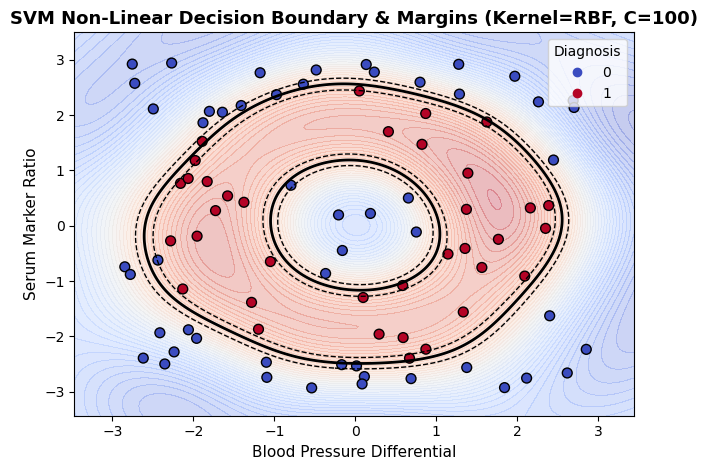

In [23]:
plt.contourf(xx, yy, Z, levels=50, cmap='coolwarm', alpha=0.3)
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=['k', 'k', 'k'], linestyles=['--', '-', '--'], linewidths=[1, 2, 1])

# Scatter test data points
scatter = plt.scatter(
    X_test['bp_diff'],
    X_test['serum_ratio'],
    c=y_test,
    cmap='coolwarm',
    edgecolors='k',
    s=50
)

kernel_used = grid_search.best_params_['svm__kernel'].upper()
c_val = grid_search.best_params_['svm__C']

plt.title(
    f"SVM Non-Linear Decision Boundary & Margins (Kernel={kernel_used}, C={c_val})",
    fontsize=13,
    fontweight='bold'
)
plt.xlabel("Blood Pressure Differential", fontsize=11)
plt.ylabel("Serum Marker Ratio", fontsize=11)
plt.legend(*scatter.legend_elements(), title="Diagnosis", loc="upper right")
plt.tight_layout()
plt.show()